In [73]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                             f1_score, precision_recall_curve, roc_curve, roc_auc_score)

# Part I – Load and Explore the MNIST Dataset

In [74]:
mnist = fetch_openml("mnist_784", as_frame=False)
X, y = mnist["data"], mnist["target"]
print(X.shape)
print(y.shape)

(70000, 784)
(70000,)


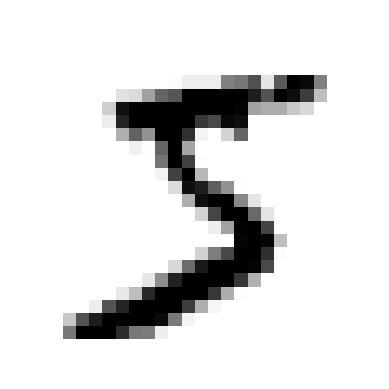

5


In [75]:
some_digit = X[0]
some_digit_image = some_digit.reshape(28, 28)
plt.imshow(some_digit_image, cmap="binary")
plt.axis("off")
plt.show()
print(y[0])

In [76]:
y = y.astype(np.uint8)

# Task 1.1– Explore the Dataset

Answer:

**1. How many images are contained in the dataset?**
**Answer:** 70,000 images.

**2. How many features does each image contain?**
**Answer:** 784 features (28 × 28 pixels).

**3. How many classes are there?**
**Answer:** 10 classes (digits 0–9).

**4. What does each feature represent?**
**Answer:** Each feature is the darkness of one pixel, from 0 (white background) to 255 (full ink).

**5. What is the target variable?**
**Answer:** The target is the digit the image shows (0–9).

**6. Explain why visual inspection is useful before training a classification model**
**Answer:** Looking at the data first lets you check that it loaded correctly, that the labels match the pictures, and how messy the handwriting is. It also reminds you what the model actually "sees": just a grid of pixel numbers, not shapes.


**For understanding of Part 1. It shows the first 10 pictures, with the stored answer as each picture's title*:*

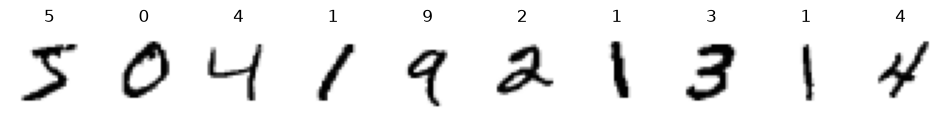

In [77]:
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(28, 28), cmap="binary")
    ax.set_title(y[i])
    ax.axis("off")
plt.show()

# Part II – Create Training and Test Sets

In [78]:
X_train = X[:60000]
X_test = X[60000:]
y_train = y[:60000]
y_test = y[60000:]

In [79]:
y_train_5 = (y_train == 5)
y_test_5 = (y_test == 5)

In [80]:
print(y_train[:10])
print(y_train_5[:10])
print(y_train_5.sum())

[5 0 4 1 9 2 1 3 1 4]
[ True False False False False False False False False False]
5421


# Task 2.1 – Understand Binary Classification

**1. What is the positive class?**
**Answer:** "The image is a 5" (True). "Positive" doesn't mean good. It just means the thing we are looking for.

**2. What is the negative class?**
**Answer:** "The image is not a 5" (False). This is every other digit: 0, 1, 2, 3, 4, 6, 7, 8 and 9.

**3. Why is this called binary classification?**
**Answer:** Because there are only two possible answers, True or False. "Binary" means made of two, like computer bits that are only 0 or 1.

# Part III – Train a Binary Classifier

In [81]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [82]:
sgd_clf.predict([some_digit])

array([ True])

In [83]:
fives = np.where(y_train == 5)[0][:5]
not_fives = np.where(y_train != 5)[0][:5]

for i in np.concatenate([fives, not_fives]):
    pred = sgd_clf.predict([X_train[i]])[0]
    print(f"index {i}: actual={y_train[i]}, is_5={y_train[i]==5}, predicted_5={pred}")

index 0: actual=5, is_5=True, predicted_5=True
index 11: actual=5, is_5=True, predicted_5=True
index 35: actual=5, is_5=True, predicted_5=True
index 47: actual=5, is_5=True, predicted_5=True
index 65: actual=5, is_5=True, predicted_5=True
index 1: actual=0, is_5=False, predicted_5=False
index 2: actual=4, is_5=False, predicted_5=False
index 3: actual=1, is_5=False, predicted_5=False
index 4: actual=9, is_5=False, predicted_5=False
index 5: actual=2, is_5=False, predicted_5=False


# Task 3.1– Generate Predictions

Test the classifier using several images. For each image, compare: the actual label, whether it is
a 5, the model prediction.
Answer:

**1. Does the classifier correctly identify all 5s?**
**Answer:** Yes, for the five 5s I tested (indices 0, 11, 35, 47 and 65), the classifier correctly predicted all of them as 5. However, this is only a small sample, so it does not prove the model finds every 5 in the dataset.

**2. Does it ever classify a non-5 as a 5?**
**Answer:** No, in my test none of the five non-5 images (indices 1–5, digits 0, 4, 1, 9 and 2) were classified as a 5. However, with only five examples this does not prove the model never makes this mistake. The confusion matrix in Part V shows it does happen across the full dataset.

**3. Why is checking only a few predictions not enough to evaluate the model?**
**Answer:** 10 cards out of 60,000 is a tiny sample. The model could be lucky on those 10 and still make thousands of mistakes elsewhere. It's like judging a student on one exam question. We need to test thousands of predictions in an organised way.


# Part IV – Accuracy and Cross-Validation

In [84]:
scores = cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")
print(scores)
print(scores.mean())

[0.95035 0.96035 0.9604 ]
0.9570333333333334


In [85]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier()
print(cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy"))

[0.90965 0.90965 0.90965]


# Task 4.1– Evaluate Accuracy

Calculate the mean cross-validation accuracy. Answer:

**1. What accuracy did you obtain?**
**Answer:**0.957 ~ 0.96 . That is 96%

**2. Is the accuracy high?**
**Answer:** It looks high. But the lazy model gets about 91% with zero skill, so our model is only about 5 points better than doing nothing.

**3. Does a high accuracy necessarily mean that the classifier is useful?**
**Answer:** No. Accuracy only counts total correct answers. It doesn't show whether the model finds the thing we care about, the 5s.

**4. What happens if the positive class is relatively rare?**
**Answer:** A model can get high accuracy just by always predicting the common class, while failing completely on the rare class. So when one class is rare (we call this imbalanced data), accuracy is misleading. We need better measures.


# Part V – Confusion Matrix

In [86]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)

In [87]:
cm = confusion_matrix(y_train_5, y_train_pred)
print(cm)

[[53892   687]
 [ 1891  3530]]


# Task 5.1– Interpret the Confusion Matrix

From your confusion matrix, identify: True positives, True negatives, False positives, False
negatives. Explain what each of these cases means for the MNIST “5” classification problem.

**Answer:** True Positives (about 3,530): images that really are 5s, and the model correctly said "5". ✅ Success.
True Negatives (about 53,892): images that are not 5s, and the model correctly said "not 5". ✅ Success.
False Positives (about 687): images that are not 5s, but the model wrongly said "5". A false alarm, for example a 3 or 8 that looks a bit like a 5.
False Negatives (about 1,891): images that are 5s, but the model said "not 5". A missed 5: it slipped through, maybe because it was written in an unusual way.

# Part VI – Precision, Recall and F1-Score

In [88]:
precision = precision_score(y_train_5, y_train_pred)
recall = recall_score(y_train_5, y_train_pred)
print("Precision:", precision)
print("Recall:", recall)

Precision: 0.8370879772350012
Recall: 0.6511713705958311


In [89]:
f1 = f1_score(y_train_5, y_train_pred)
print("F1-score:", f1)

F1-score: 0.7325171197343847


# Task 6.1– Interpret Precision and Recall

Answer:

**1. What does precision tell you?**
**Answer:** When the model predicts "5", how often it is actually right. In other words, how trustworthy its positive predictions are.

**2. What does recall tell you?**
**Answer:** Out of all the real 5s, what share the model found. In other words, how good it is at catching the positives.

**3. What does the F1-score tell you?**
**Answer:** A single score combining precision and recall. It is high only when both are high, so it's useful for comparing models.

**4. Which metric would be more important if false positives were very costly?**
**Answer:** Precision, because you want the model to say "yes" only when it is really sure.

**5. Which metric would be more important if false negatives were very costly?**
**Answer:** Recall, because you want to miss as few real cases as possible.


Give one real-world example where:

• high precision is particularly important;
• high recall is particularly important

**Answer:** 

- For High Precision: If a real job offer is wrongly sent to spam (a false positive), you might never see it. It's better to let a few spam emails through.
- For High Recall: In cancer screening, Missing a real cancer (a false negative) can cost a life. A false alarm only means an extra test.

# Part VII – Precision/Recall Trade-off

In [90]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3, method="decision_function")
print(y_scores[:10])

[  1200.93051237 -26883.79202424 -33072.03475406 -15919.5480689
 -20003.53970191 -16652.87731528 -14276.86944263 -23328.13728948
  -5172.79611432 -13873.5025381 ]


In [91]:
for threshold in [-5000, -2000, 0, 2000, 4000, 6000, 8000]:
    y_pred_t = (y_scores >= threshold)
    p = precision_score(y_train_5, y_pred_t, zero_division=0)
    r = recall_score(y_train_5, y_pred_t)
    print(f"{threshold:>6} | precision={p:.3f} | recall={r:.3f}")

 -5000 | precision=0.624 | recall=0.855
 -2000 | precision=0.777 | recall=0.741
     0 | precision=0.837 | recall=0.651
  2000 | precision=0.878 | recall=0.543
  4000 | precision=0.909 | recall=0.453
  6000 | precision=0.924 | recall=0.358
  8000 | precision=0.935 | recall=0.287


| Threshold | Precision | Recall |
|----------:|----------:|-------:|
| -5000 | 0.624 | 0.855 |
| -2000 | 0.777 | 0.741 |
| 0 | 0.837 | 0.651 |
| 2000 | 0.878 | 0.543 |
| 4000 | 0.909 | 0.453 |
| 6000 | 0.924 | 0.358 |
| 8000 | 0.935 | 0.287 |

# Task 7.1 – Investigate the Threshold

**1. What happens to precision when the threshold increases?**
**Answer:** It goes up (it may wobble a little, but the trend is up). The model only says "5" when it is very confident, so there are fewer false alarms.

**2. What happens to recall? It goes down. More real 5s fall below the pass mark and get missed.**
**Answer:** More real 5s fall below the pass mark and get missed.

**3. Why does changing the threshold affect the two metrics?
**Answer:** The threshold decides how many pictures get called "5". A higher threshold means fewer "5" answers: fewer false positives (precision up) but more false negatives (recall down). A lower threshold does the opposite. Both metrics depend on the same cut-off, so moving it shifts the balance between them.

**4. Is there one threshold that is always best?**
**Answer:**  No. The best threshold depends on which mistake costs more in the real situation. A spam filter wants a high threshold (precision). A cancer screen wants a low one (recall).

# Part VIII – Precision-Recall Curve

In [92]:
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

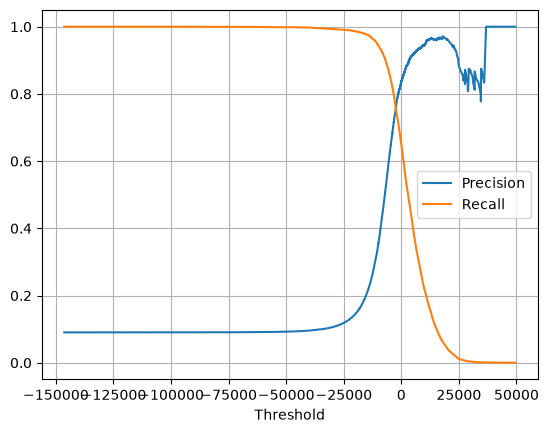

In [93]:
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.grid()
plt.legend()
plt.show()

# Task 8.1 – Interpret the Precision-Recall Curve

**1. What happens to precision as the threshold increases? 
**Answer:** It increases. The model becomes stricter, so its "5" answers become more reliable.

**2. What happens to recall? 
**Answer:** It decreases. The stricter model misses more real 5s.

**3. How could a company choose an appropriate threshold? 
**Answer:** First decide which mistake is more expensive for the business. Set a target, for example "at least 90% precision". Use the curve to find the threshold that meets the target, and check that the other metric is still acceptable at that point.

**4. Why might the default threshold not always be appropriate? 
**Answer:** The default (0) is just the model's built-in cut-off. It knows nothing about the business's costs, or about how rare the positive class is. The best balance depends on the real-world goal, so the threshold usually needs to be chosen on purpose.

# Part IX – ROC Curve and ROC-AUC

In [94]:
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

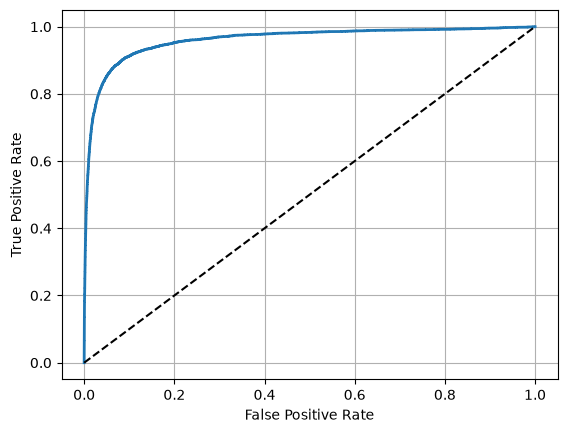

In [95]:
plt.plot(fpr, tpr, linewidth=2)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid()
plt.show()

In [96]:
roc_auc = roc_auc_score(y_train_5, y_scores)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9604938554008616


# Task 9.1 – Interpret ROC-AUC

**1. What does the ROC curve represent?**
**Answer:** How well the model separates positives from negatives at every possible threshold. Each point on the curve is one threshold, showing how many positives it catches against how many false alarms it raises.

**2. What do the x-axis and y-axis represent?** 
**Answer:** The x-axis is the False Positive Rate: the share of real non-5s wrongly called 5. The y-axis is the True Positive Rate (recall): the share of real 5s correctly found.

**3. What does a ROC-AUC value close to 1 indicate?** 
**Answer:** An excellent model. It almost always gives real 5s higher scores than non-5s, so it separates the two classes very well.

**4. What does a value close to 0.5 indicate?** 
**Answer:** The model is no better than random guessing.

# Part X – Multiclass Classification

In [97]:
sgd_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [98]:
some_digit_scores = sgd_clf.decision_function([some_digit])
print(some_digit_scores)

[[-31893.03095419 -19047.55566534  -9530.63950739   1823.73154031
  -22320.14822878  -1385.80478895 -26188.91070951 -16147.51323997
   -4604.35491274 -12050.767298  ]]


In [99]:
print(sgd_clf.classes_)
print(sgd_clf.classes_[some_digit_scores.argmax()])

[0 1 2 3 4 5 6 7 8 9]
3


# Task 10.1 – Understand Multiclass Classification

**1. How many classes are being predicted?**
**Answer:** 10 (the digits 0–9).

**2. What does the decision score represent?** 
**Answer:** How strongly the model believes the picture belongs to each class. There is one score per digit, and a higher score means more confident.

**3. Which class has the highest score?** 
**Answer:** Read from your output. It's the digit printed by the argmax line.

**4. Does the model need to be trained separately for every class?** 
**Answer:** Not by you, because one fit call is enough. But internally, scikit-learn trains a separate binary classifier for each class (10 in total) using the One-vs-Rest strategy, and picks the class whose classifier gives the highest score.

# Part XI – Evaluate the Multiclass Classifier

In [100]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train, cv=3)

In [101]:
conf_mx = confusion_matrix(y_train, y_train_pred)
print(conf_mx)

[[5565    0   69   16   21   73   50   13   83   33]
 [   3 6399   95   20   15   47   16   17  110   20]
 [  33   56 5202   93   69   42  158   74  213   18]
 [  12   32  218 4953   24  446   33   66  212  135]
 [  11   26   47    5 5285   25   70   36   83  254]
 [  40   23   58  149   85 4631  166   23  156   90]
 [  24   11   66    6   26  115 5627    4   37    2]
 [  22   24  103   33  124   41   10 5221   72  615]
 [  26  101  156  121   48  461   76   47 4647  168]
 [  23   14   55   72  503  125    5  447  123 4582]]


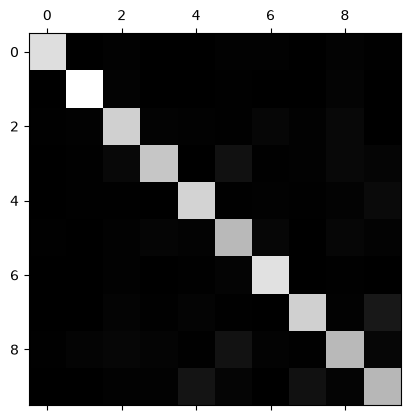

In [102]:
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.show()

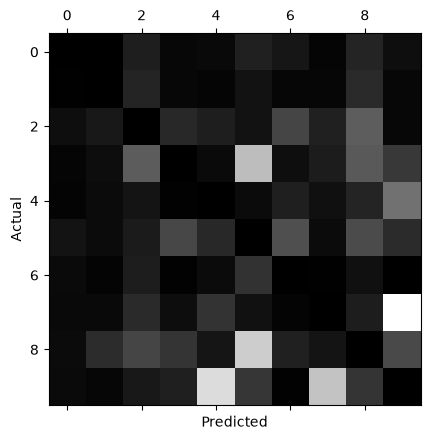

In [103]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Task 11.1 – Analyze Classification Errors

Check these against your own plot. They're what the textbook found.

**Which digits appear to be confused most often?** 
**Answer:** 3 and 5 get mixed up with each other. Many digits are wrongly guessed as 8 (the 8 column is bright). 4 and 9, and 7 and 9, are also confused. These pairs share similar strokes and loops.

**Which digits appear to be easier to classify?** 
**Answer:** Usually 0, 1 and 6. Their rows stay dark in the error plot, because their shapes are simple and distinctive.

**Why can a confusion matrix be more informative than a single accuracy value?** 
**Answer:** Accuracy only tells you how often the model is wrong. The confusion matrix shows which digits it confuses with which. That tells you what to improve, for example collecting more 3s and 5s, or helping the model tell loops apart.

# Part XII – Multilabel Classification

In [104]:
y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

In [105]:
print(y_train[:5])
print(y_multilabel[:5])

[5 0 4 1 9]
[[False  True]
 [False False]
 [False False]
 [False  True]
 [ True  True]]


In [106]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)
knn_clf.predict([some_digit])

array([[False,  True]])

# Task 12.1 – Understand Multilabel Classification

**1. What makes this problem different from ordinary multiclass classification?** 
**Aswer:** In multiclass, each picture gets exactly one class out of many. In multilabel, each picture gets several independent yes/no labels at once. A 9, for example, is both "large" and "odd".

**2. How many labels can an observation receive?** 
**Aswer:** Here there are two labels, each True or False, which gives 4 possible combinations. In general, an observation can receive anywhere from none to all of the labels.

**3. What does the prediction for a single image represent?** 
**Aswer:** Two separate answers about the same picture: [is it large (7 or more)?, is it odd?]. For picture 0 it says "not large, but odd".

# Part XIII – Multilabel Evaluation

In [114]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)

In [115]:
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.9764102655606048

# Task 13.1 – Interpret the Result

**1. Why is evaluating a multilabel classifier different from evaluating a binary classifier?** 
**Answer:** A binary classifier has only one yes/no answer to check per picture. A multilabel classifier has several answers per picture, so each label must be scored and then combined. You have to choose how to combine them (for example macro, a simple average, or weighted, which gives more weight to labels with more examples), and that choice changes the final number.

**2. Why should the evaluation metric be selected according to the problem?** 
**Answer:** Different metrics measure different things, and the right one depends on the real-world goal: which mistakes are expensive, whether some classes are rare, and whether all labels matter equally. This lab showed that the same model can look great on one metric (96% accuracy) and weak on another (65% recall). The wrong metric can make a bad model look good.